In [13]:
import os, uuid, hashlib, platform, getpass
# ===== 1. 填写学号 =====
STUDENT_ID = 20244080116 #修改为自己的学号
# ===== 2. 打印 conda 环境 =====
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
# ===== 3. 机器指纹（绑定当前电脑）=====
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
# ===== 4. 生成唯一 ID =====
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] D:\conda\conda_envs\myenv1
[学号] 20244080116
[机器指纹] 5ec80ac0c8f60ff8
[RUN_ID] 20244080116-5ec80ac0c8f60ff8


热⾝：定义简单函数

1. 定义⼀个名为 say_hi 的函数，它不接受任何参数，并在被调⽤时打印字符串
"Hello, world!"。
2. 定义⼀个名为 goat_pad 的函数，它接受⼀个字符串作为其唯⼀参数，并打印该字
符串，前后都加上字符串 "goat"。
3. 定义⼀个名为 print_n 的函数，它接受两个参数，⼀个字符串 s 和⼀个整数 n，并
打印字符串 n 次，每次在单独的⼀⾏上。

In [14]:
# 1. 定义 say_hi 函数，打印 "Hello, world!"
def say_hi():
    print("Hello, world!")

# 调用测试
say_hi()


# 2. 定义 goat_pad，接收一个字符串参数 text，返回 "goat" + text + "goat"
def goat_pad(text):
    res = "goat" + text + "goat"
    print(res)

# 调用测试
goat_pad("ABC")


# 3. print_n，接收一个字符串和一个整数 n，打印该字符串 n 次
def print_n(s, n):
    for _ in range(n):
        print(s)

# 调用测试
print_n("test", 3)

Hello, world!
goatABCgoat
test
test
test


欧⼏⾥得算法

欧⼏⾥得算法是⼀种寻找两个数的最⼤公约数（GCD）的⽅法。回想⼀下，两个数m和n
的最⼤公约数是同时能整除m和n的最⼤数。
1. 实现⼀个名为gcd的函数，它接受两个整数作为其参数并返回它们的GCD。你可以
假设两个输⼊都是整数，所以你不需要在你的函数中包含任何错误检查。
2. 使⽤你的函数评估以下数字对的GCD：
1. (2018, 2019)
2. (1200, 300)
3. (5040, 60)
3. 如果⼀个或两个参数是负数，你的函数会做什么？这种⾏为有意义吗？

取模运算后最终返回**正数**。因为公约数定义：能同时整除两个数，正负号不影响整除关系。数学上最大公约数一般定义为**非负整数**，所以这个行为**是有意义的**。

In [15]:
def gcd(m, n):
    while n != 0:
        m, n = n, m % n
    return m


# 测试三组数字对
print(f"gcd(2018, 2019) = {gcd(2018, 2019)}")
print(f"gcd(1200, 300) = {gcd(1200, 300)}")
print(f"gcd(5040, 60) = {gcd(5040, 60)}")


# 测试负数情况
print("\n====测试负数参数====")
print(f"gcd(-1200, 300) = {gcd(-1200, 300)}")
print(f"gcd(-24, -18) = {gcd(-24, -18)}")

gcd(2018, 2019) = 1
gcd(1200, 300) = 300
gcd(5040, 60) = 60

====测试负数参数====
gcd(-1200, 300) = 300
gcd(-24, -18) = -6


近似欧拉数e

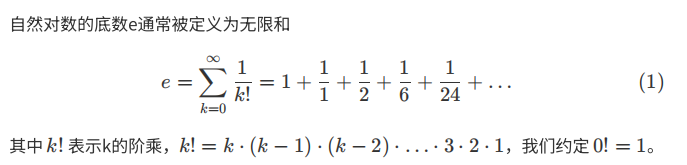

1. 欧拉数的⼀个早期特征，归功于雅各布·伯努利，是作为极限
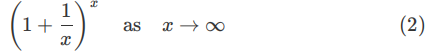

定义⼀个名为euler_limit的函数，它接受⼀个整数 作为参数，并返回⼀个浮点
数，通过上述公式中取 来近似e。

In [16]:
import math

def euler_limit(n):
    return (1 + 1 / n) ** n

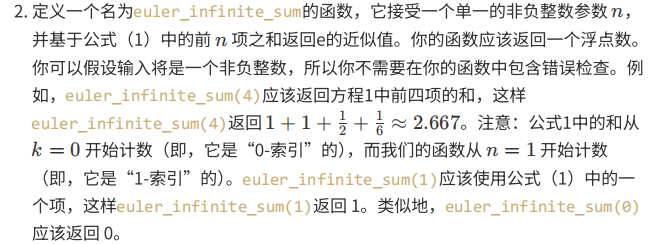

In [17]:
def euler_infinite_sum(n):
    if n == 0:
        return 0.0
    total = 0.0
    fact = 1  # 0! = 1
    for k in range(n):
        if k == 0:
            fact = 1
        else:
            fact = fact * k
        total += 1.0 / fact
    return total

# 测试示例
print(euler_infinite_sum(1))  
print(euler_infinite_sum(4))  

1.0
2.6666666666666665


3. 定义⼀个名为euler_approx的函数，它接受⼀个单⼀的参数，⼀个浮点数 ，并使
⽤公式（1）中的和来获得⼀个近似e的值，该值在 内接近真实值e。提⽰：使⽤
while循环。注意：你可以使⽤Python的math模块来获得e的真实值（直到浮点精
度）：math.exp(1)。

In [18]:
def euler_approx(eps):
    true_e = math.exp(1)
    total = 0.0
    k = 0
    fact = 1
    while abs(true_e - total) > eps:
        if k == 0:
            fact = 1
        else:
            fact = fact * k
        total += 1.0 / fact
        k += 1
    return total

4. 定义⼀个名为print_euler_sum_table的函数，它接受⼀个单⼀的正整数n 作为
参数，并打印从euler_infinite_sum(k)获得的值， k的范围从1到n ，每⾏⼀
个。

In [19]:
def print_euler_sum_table(n):
    for k in range(1, n+1):
        val = euler_infinite_sum(k)
        print(val)

# ========测试代码========
print("====测试 euler_limit====")
print(euler_limit(10000))

print("\n====测试 euler_infinite_sum====")
print(euler_infinite_sum(1))
print(euler_infinite_sum(4))

print("\n====测试 euler_approx，误差0.001====")
print(euler_approx(0.001))

print("\n====测试 print_euler_sum_table(5)====")
print_euler_sum_table(5)

====测试 euler_limit====
2.7181459268249255

====测试 euler_infinite_sum====
1.0
2.6666666666666665

====测试 euler_approx，误差0.001====
2.7180555555555554

====测试 print_euler_sum_table(5)====
1.0
2.0
2.5
2.6666666666666665
2.708333333333333


测试整数属性

在这个问题中，你将得到更多关于条件的练习，并对典型的“编程⾯试”问题所需的思
维⽅式有⼀个初步的了解。⼀个正整数 是2的幂，如果对于某个整数

1. 编写⼀个名为is_power_of_2的函数，它接受⼀个正整数作为其唯⼀的参数，并返
回⼀个布尔值，指⽰输⼊是否是2的幂。你可以假设输⼊是⼀个正整数。你不能在
你的解决⽅案中使⽤内置的math.sqrt函数。你应该只需要使⽤除法和模（%）运
算。

In [20]:
def is_power_of_2(n):
    # 不断除以2，直到不能整除
    while n % 2 == 0:
        n = n // 2
    # 最后剩下等于1，说明是2的幂
    return n == 1

2. 将你之前的解决⽅案推⼴到⼀个名为is_power的函数，它接受两个正整数作为其
参数， 和 ，按那个顺序，并返回⼀个布尔值。is_power(b,n)如果 是 的幂
则返回True，否则返回False。

In [21]:
def is_power(b, n):
    # n=1的特殊情况：任何b的0次方都是1
    if n == 1:
        return True
    while n % b == 0:
        n = n // b
    return n == 1

# 测试样例
print("====is_power_of_2测试====")
print(is_power_of_2(1))   # True，2^0 =1
print(is_power_of_2(8))   # True，2^3=8
print(is_power_of_2(10))  # False

print("\n====is_power测试====")
print(is_power(3, 27))    # True 3^3=27
print(is_power(5, 125))   # True 5^3=125
print(is_power(2, 10))    # False
print(is_power(4, 1))     # True，任何数0次方等于1

====is_power_of_2测试====
True
True
False

====is_power测试====
True
True
False
True
